# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : RIZKY WISNUSAPUTRA
- NIM   : 241011401458
- Kelas : Reg B 

In [ ]:
%pip install pandas numpy matplotlib

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [2]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 58  # 2 digit terakhir NIM 241011401458

In [3]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.2, random_state=None):
    """Membagi data menjadi train & test secara acak (reproducible lewat random_state)."""
    rng = np.random.RandomState(random_state)
    n_samples = X.shape[0]
    indices = rng.permutation(n_samples)          # acak urutan indeks
    n_test = int(n_samples * test_size)           # jumlah data testing
    test_idx, train_idx = indices[:n_test], indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


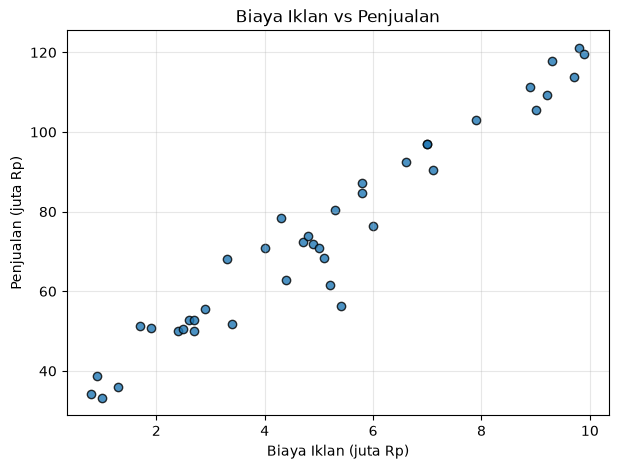

In [4]:
# Jawaban A1
# 1. Baca data, tampilkan 5 data pertama dan jumlah baris
df_ads = pd.read_csv('Ads_Data.csv')
display(df_ads.head())
print('Jumlah baris data:', len(df_ads))

# 2. Pisahkan X (2 dimensi) dan y
X = df_ads[['BiayaIklan']].values      # shape (n, 1)
y = df_ads['Penjualan'].values         # shape (n,)
print('Shape X:', X.shape, '| Shape y:', y.shape)

# 3. Scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(7, 5))
plt.scatter(X, y, color='tab:blue', edgecolor='k', alpha=0.8)
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [5]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [ ]:
# Jawaban A3
class LinearRegression:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def fit(self, X, y):
        Xb = np.c_[np.ones((X.shape[0], 1)), X]          
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

lin_reg = LinearRegression().fit(X_train, y_train)
b_ne, m_ne = lin_reg.intercept_, lin_reg.coef_[0]

print(f'Intercept (b)  : {b_ne:.4f}')
print(f'Koefisien (m)  : {m_ne:.4f}')
print(f'Persamaan      : y_hat = {b_ne:.4f} + {m_ne:.4f} * X')

Intercept (b)  : 26.9641
Koefisien (m)  : 9.3156
Persamaan      : y_hat = 26.9641 + 9.3156 * X


**Jawaban A3 (interpretasi):**

Hasil training (normal equation, `random_state=58`) memberikan intercept $b = 26.9641$ dan koefisien $m = 9.3156$, sehingga persamaan regresinya adalah $\hat{y} = 26.9641 + 9.3156\,X$.

Nilai $m = 9.3156$ berarti setiap kenaikan biaya iklan sebesar 1 juta Rp, penjualan bulanan rata-rata naik sekitar 9.32 juta Rp. Nilai intercept $b = 26.96$ adalah perkiraan penjualan dasar ketika biaya iklan 0; angka ini hanya patokan garis karena data terkecil kami ada di biaya iklan 0.8 juta, bukan 0.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [7]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = lin_reg.predict(X_train)
y_pred_test  = lin_reg.predict(X_test)

hasil_eval_A = pd.DataFrame({
    'MAE' : [mae(y_train, y_pred_train),  mae(y_test, y_pred_test)],
    'MSE' : [mse(y_train, y_pred_train),  mse(y_test, y_pred_test)],
    'RMSE': [rmse(y_train, y_pred_train), rmse(y_test, y_pred_test)],
    'R2'  : [r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test)],
}, index=['Training', 'Testing'])
display(hasil_eval_A.round(4))
print('Std y_train:', round(np.std(y_train), 4), '| Std y_test:', round(np.std(y_test), 4))

,MAE,MSE,RMSE,R2
Training,4.3504,36.2741,6.0228,0.9472
Testing,5.1478,36.7506,6.0622,0.8611


Std y_train: 26.2115 | Std y_test: 16.2653


**Jawaban A4 (analisis):**

| Data | MAE | MSE | RMSE | $R^2$ |
|---|---|---|---|---|
| Training | 4.3504 | 36.2741 | 6.0228 | 0.9472 |
| Testing | 5.1478 | 36.7506 | 6.0622 | 0.8611 |

- RMSE ≈ 6.06 pada data testing artinya prediksi penjualan model rata-rata meleset sekitar 6 juta Rp dari nilai sebenarnya. Angka ini kecil dibandingkan sebaran penjualan yang berkisar sekitar 33 s.d. 121 juta Rp (standar deviasi `y_train` ≈ 26.2).
- $R^2$ = 0.9472 (training) dan 0.8611 (testing) artinya biaya iklan menjelaskan sekitar 94.7% variasi penjualan pada data training dan sekitar 86.1% pada data testing.
- $R^2$ testing lebih rendah, tetapi RMSE training (6.02) dan testing (6.06) hampir sama. Jadi turunnya $R^2$ bukan tanda overfitting yang serius, melainkan karena data testing hanya 8 titik dengan sebaran penjualan yang lebih sempit (std ≈ 16.3), sehingga $R^2$ mudah berubah.
- Kesimpulan: model ini sudah cukup baik untuk model sederhana dengan satu fitur. Keterbatasannya: hanya memakai biaya iklan (faktor lain seperti musim atau promo tidak masuk) dan data testing sangat sedikit, jadi angkanya belum terlalu stabil.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

--- Training learning_rate = 0.001 ---
--- Training learning_rate = 0.02 ---
--- Training learning_rate = 0.1 ---


C:\Users\USER\AppData\Local\Temp\ipykernel_22372\1693642155.py:16: RuntimeWarning: overflow encountered in square
  self.loss_history.append(np.mean(error ** 2))      # MSE
C:\Users\USER\AppData\Local\Temp\ipykernel_22372\1693642155.py:19: RuntimeWarning: overflow encountered in matmul
  dm = (2 / n_samples) * (X.T @ error)
C:\Users\USER\AppData\Local\Temp\ipykernel_22372\1693642155.py:21: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= self.learning_rate * dm


,Intercept (b),Koefisien (m),MSE akhir (train)
Metode,,,
Normal Equation,26.964102,9.315614,36.274099
GD (lr=0.001),23.621292,9.811772,38.574747
GD (lr=0.02),26.964102,9.315614,36.274099
GD (lr=0.1),NaN,NaN,NaN


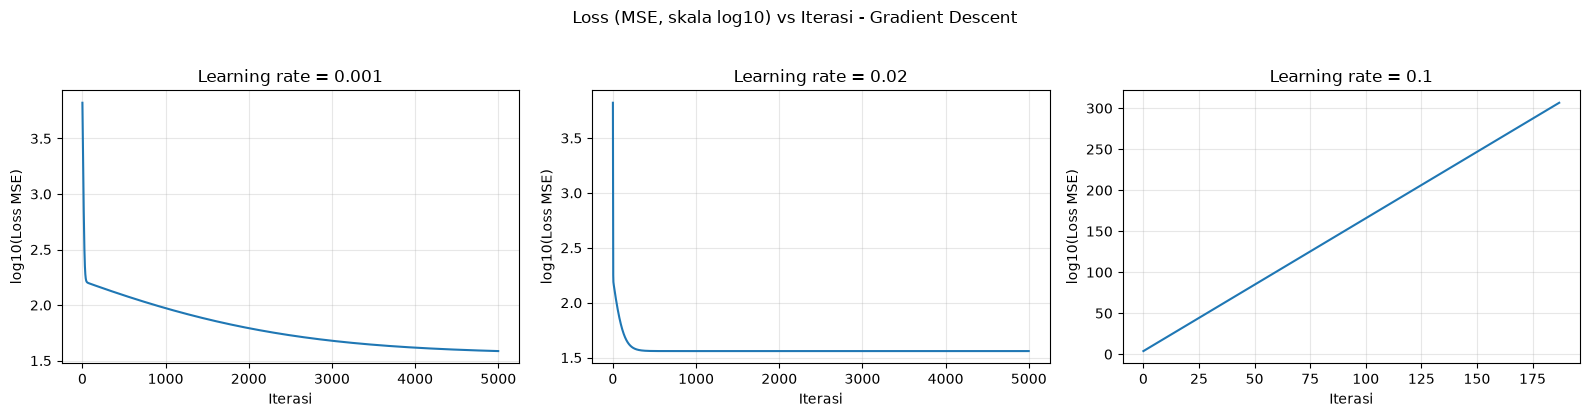

Eigenvalue Hessian: terkecil = 0.4026, terbesar = 74.5112
Batas learning rate stabil = 2 / lambda_max = 0.0268
lr=0.1 -> loss pertama kali tidak finite pada iterasi ke- 188
lr=0.1 -> loss pada beberapa iterasi awal: [6.63049063e+03 2.69222222e+05 1.11978954e+07 4.66016009e+08
 1.93941460e+10 8.07124639e+11]


In [ ]:
# Jawaban A5
class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent (loss = MSE)."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.intercept_ = 0.0
        self.coef_ = np.zeros(n_features)
        self.loss_history = []
        for _ in range(self.n_iterations):
            y_pred = self.intercept_ + X @ self.coef_
            error = y_pred - y
            self.loss_history.append(np.mean(error ** 2))      
            # gradien MSE terhadap b dan m
            db = (2 / n_samples) * np.sum(error)
            dm = (2 / n_samples) * (X.T @ error)
            self.intercept_ -= self.learning_rate * db
            self.coef_ -= self.learning_rate * dm
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_

learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
for lr in learning_rates:
    print(f'--- Training learning_rate = {lr} ---')
    gd_models[lr] = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)

# Perbandingan dengan Normal Equation (Soal A3)
baris = [{'Metode': 'Normal Equation', 'Intercept (b)': b_ne, 'Koefisien (m)': m_ne,
          'MSE akhir (train)': mse(y_train, lin_reg.predict(X_train))}]
for lr, model in gd_models.items():
    baris.append({'Metode': f'GD (lr={lr})', 'Intercept (b)': model.intercept_,
                  'Koefisien (m)': model.coef_[0], 'MSE akhir (train)': model.loss_history[-1]})
display(pd.DataFrame(baris).set_index('Metode'))

# Grafik loss vs iterasi. Sumbu-y = log10(MSE) supaya loss yang meledak (lr=0.1) tetap bisa digambar
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, lr in zip(axes, learning_rates):
    loss = np.array(gd_models[lr].loss_history, dtype=float)
    valid = np.isfinite(loss) & (loss > 0)                 
    loss_log10 = np.full_like(loss, np.nan)
    loss_log10[valid] = np.log10(loss[valid])
    ax.plot(loss_log10)
    ax.set_title(f'Learning rate = {lr}')
    ax.set_xlabel('Iterasi'); ax.set_ylabel('log10(Loss MSE)')
    ax.grid(alpha=0.3)
plt.suptitle('Loss (MSE, skala log10) vs Iterasi - Gradient Descent', y=1.03)
plt.tight_layout(); plt.show()

# Batas learning rate agar GD stabil: lr < 2 / lambda_max, dengan Hessian MSE = (2/n) * Xb^T Xb
Xb_train = np.c_[np.ones(len(X_train)), X_train]
eig = np.linalg.eigvalsh(2 * Xb_train.T @ Xb_train / len(X_train))
print(f'Eigenvalue Hessian: terkecil = {eig.min():.4f}, terbesar = {eig.max():.4f}')
print(f'Batas learning rate stabil = 2 / lambda_max = {2 / eig.max():.4f}')

# Iterasi pertama loss menjadi tak hingga / NaN pada lr=0.1
loss_div = np.array(gd_models[0.1].loss_history, dtype=float)
idx_bad = np.where(~np.isfinite(loss_div))[0]
print('lr=0.1 -> loss pertama kali tidak finite pada iterasi ke-', idx_bad[0] if len(idx_bad) else 'tidak ada')
print('lr=0.1 -> loss pada beberapa iterasi awal:', loss_div[:6])

**Jawaban A5 (analisis):**

Perbandingan hasil ketiga learning rate dengan normal equation:

| Metode | Intercept (b) | Koefisien (m) | MSE akhir (train) |
|---|---|---|---|
| Normal Equation | 26.9641 | 9.3156 | 36.2741 |
| GD, lr = 0.001 | 23.6213 | 9.8118 | 38.5747 |
| GD, lr = 0.02 | 26.9641 | 9.3156 | 36.2741 |
| GD, lr = 0.1 | NaN | NaN | NaN |

Learning rate 0.001 terlalu lambat. Setelah 5000 iterasi hasilnya belum sampai ke solusi normal equation (intercept masih 23.62, padahal seharusnya 26.96), dan di grafik terlihat loss nya masih turun pelan. Langkah tiap iterasinya terlalu kecil, jadi 5000 iterasi belum cukup.

Learning rate 0.02 sudah pas. Loss turun cepat lalu mulai datar sekitar iterasi ke-400, dan hasil akhirnya sama dengan normal equation (b = 26.9641 dan m = 9.3156).

Learning rate 0.1 gagal konvergen (divergen). Langkahnya terlalu besar, sehingga tiap update malah melewati titik minimum dan jaraknya jadi makin jauh. Loss-nya terus membesar, dari sekitar 6.6×10³ di iterasi pertama menjadi 2.7×10⁵, lalu 1.1×10⁷, naik sekitar 41 kali lipat tiap iterasi. Pada iterasi ke-188 nilainya sudah terlalu besar, sehingga intercept dan koefisien akhirnya menjadi NaN.

Peringatan `RuntimeWarning: overflow` muncul karena angkanya sudah melewati batas yang bisa disimpan float64, jadi berubah menjadi `inf`. Setelah itu operasi `inf - inf` menghasilkan NaN. Warning ini menandakan bahwa learning rate 0.1 terlalu besar untuk data ini.

Dari hasil perhitungan, batas learning rate yang aman untuk data ini sekitar 0.0268 (dihitung dari 2 dibagi eigenvalue terbesar Hessian, yaitu 74.51). Learning rate 0.02 masih di bawah batas itu sehingga konvergen, sedangkan 0.1 di atasnya sehingga divergen. Batasnya kecil karena nilai `BiayaIklan` belum dinormalisasi (nilainya sampai sekitar 10). Learning rate 0.001 memang aman, tetapi terlalu kecil sehingga konvergensinya sangat lambat.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

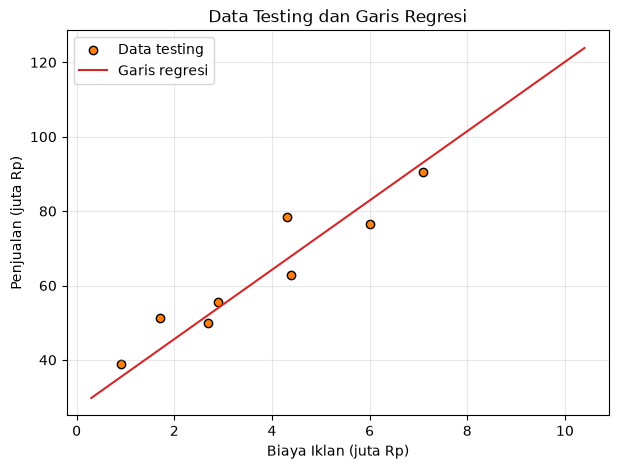

,BiayaIklan (juta),Prediksi Penjualan (juta)
0,4.5,68.884
1,7.0,92.173
2,12.0,138.751


Rentang BiayaIklan pada data: 0.8 s.d. 9.9


In [ ]:
# Jawaban A6
# 1. Scatter data testing + garis regresi
x_line = np.linspace(X.min() - 0.5, X.max() + 0.5, 100).reshape(-1, 1)
plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, color='tab:orange', edgecolor='k', label='Data testing')
plt.plot(x_line, lin_reg.predict(x_line), color='tab:red', label='Garis regresi')
plt.title('Data Testing dan Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.legend(); plt.grid(alpha=0.3); plt.show()

# 2. Prediksi untuk biaya iklan baru
biaya_baru = np.array([[4.5], [7.0], [12.0]])
pred_baru = lin_reg.predict(biaya_baru)
display(pd.DataFrame({'BiayaIklan (juta)': biaya_baru.ravel(),
                      'Prediksi Penjualan (juta)': pred_baru}).round(3))
print('Rentang BiayaIklan pada data:', X.min(), 's.d.', X.max())

**Jawaban A6 (analisis):**

Prediksi penjualan dari persamaan $\hat{y} = 26.9641 + 9.3156\,X$:

| Biaya iklan (juta Rp) | Prediksi penjualan (juta Rp) |
|---|---|
| 4.5 | 68.88 |
| 7.0 | 92.17 |
| 12.0 | 138.75 |

Prediksi untuk 4.5 dan 7 juta berada di dalam rentang data (0.8 s.d. 9.9 juta), sehingga cukup bisa dipercaya dengan kesalahan tipikal sekitar 6 juta Rp (RMSE).

Prediksi untuk 12 juta adalah ekstrapolasi, dan menurut saya kurang bisa dipercaya. Biaya 12 juta berada di luar rentang data, dan hasil 138.75 juta lebih tinggi dari seluruh penjualan yang pernah teramati (maksimum 121.1 juta). Model hanya membuktikan hubungan linear di rentang data yang ada; tidak ada bukti bahwa pola yang sama berlanjut di luar rentang itu. Dalam praktiknya efek iklan biasanya menurun (diminishing returns) karena pasar mulai jenuh, sehingga penjualan nyata kemungkinan lebih rendah dari 138.75. Nilai RMSE ≈ 6 juga hanya berlaku di dalam rentang data, dan ketidakpastian prediksi makin besar semakin jauh dari data.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah baris data: 60
Spam
Bukan Spam (0)    35
Spam (1)          25
Name: count, dtype: int64
Shape X: (60, 2) | Shape y: (60,)


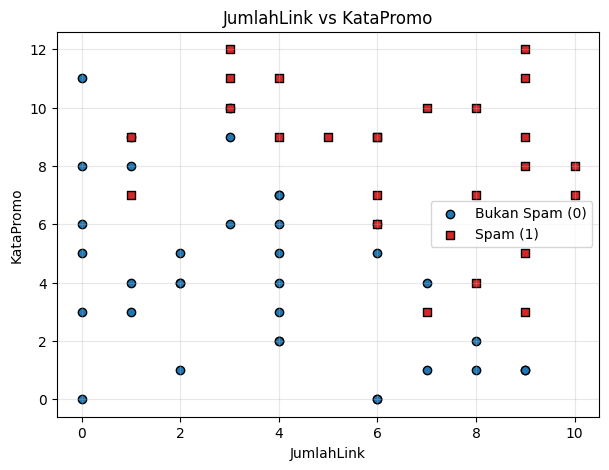

In [ ]:
# Jawaban B1
# 1. Baca data, 5 data pertama, jumlah Spam bukan Spam
df_email = pd.read_csv('Email_Data.csv')
display(df_email.head())
print('Jumlah baris data:', len(df_email))
print(df_email['Spam'].value_counts().rename({0: 'Bukan Spam (0)', 1: 'Spam (1)'}))

# 2. Pisahkan X dan y
Xe = df_email[['JumlahLink', 'KataPromo']].values
ye = df_email['Spam'].values
print('Shape X:', Xe.shape, '| Shape y:', ye.shape)

# 3. Scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(Xe[ye == 0, 0], Xe[ye == 0, 1], color='tab:blue', edgecolor='k', label='Bukan Spam (0)')
plt.scatter(Xe[ye == 1, 0], Xe[ye == 1, 1], color='tab:red', marker='s', edgecolor='k', label='Spam (1)')
plt.title('JumlahLink vs KataPromo')
plt.xlabel('JumlahLink'); plt.ylabel('KataPromo')
plt.legend(); plt.grid(alpha=0.3); plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Xe_train:

 (45, 2) | Xe_test: (15, 2)
Proporsi Spam -> train: 0.422 | test: 0.4


Intercept (b)        : -10.4196
Koefisien m1 (Link)  : 0.8593
Koefisien m2 (Promo) : 0.8887
P(Spam) = sigmoid(-10.4196 + 0.8593*JumlahLink + 0.8887*KataPromo)


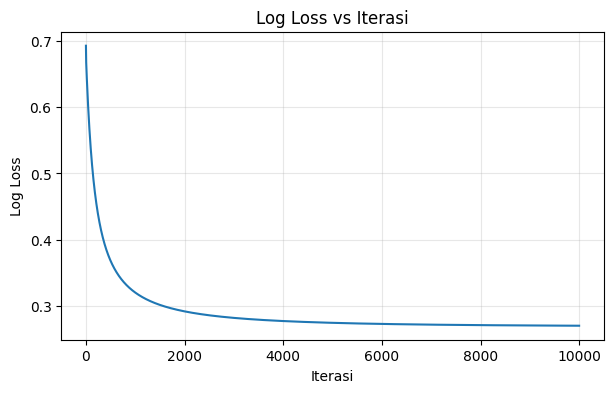

Log loss awal : 0.6931
Log loss iterasi 1000 : 0.32
Log loss iterasi 5000 : 0.2742
Log loss akhir: 0.2698


In [ ]:
# Jawaban B2
# 1. Split data
Xe_train, Xe_test, ye_train, ye_test = train_test_split(Xe, ye, test_size=0.25, random_state=RANDOM_STATE)
print('Xe_train:', Xe_train.shape, '| Xe_test:', Xe_test.shape)
print('Proporsi Spam -> train:', ye_train.mean().round(3), '| test:', ye_test.mean().round(3))

# 2. Model Logistic Regression (Gradient Descent)
class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    @staticmethod
    def _sigmoid(z):
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))    # agar tidak overflow

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.intercept_ = 0.0
        self.coef_ = np.zeros(n_features)
        self.loss_history = []
        eps = 1e-15
        for _ in range(self.n_iterations):
            p = self._sigmoid(self.intercept_ + X @ self.coef_)
            p_clip = np.clip(p, eps, 1 - eps)
            self.loss_history.append(-np.mean(y * np.log(p_clip) + (1 - y) * np.log(1 - p_clip)))  # log loss
            error = p - y
            self.intercept_ -= self.learning_rate * np.mean(error)
            self.coef_ -= self.learning_rate * (X.T @ error) / n_samples
        return self

    def predict_proba(self, X):
        return self._sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(Xe_train, ye_train)

# 3. Intercept, koefisien, persamaan
b_lg, (m1_lg, m2_lg) = log_reg.intercept_, log_reg.coef_
print(f'Intercept (b)        : {b_lg:.4f}')
print(f'Koefisien m1 (Link)  : {m1_lg:.4f}')
print(f'Koefisien m2 (Promo) : {m2_lg:.4f}')
print(f'P(Spam) = sigmoid({b_lg:.4f} + {m1_lg:.4f}*JumlahLink + {m2_lg:.4f}*KataPromo)')

# 4. Grafik log loss vs iterasi
plt.figure(figsize=(7, 4))
plt.plot(log_reg.loss_history)
plt.title('Log Loss vs Iterasi')
plt.xlabel('Iterasi'); plt.ylabel('Log Loss')
plt.grid(alpha=0.3); plt.show()
print('Log loss awal :', round(log_reg.loss_history[0], 4))
print('Log loss iterasi 1000 :', round(log_reg.loss_history[999], 4))
print('Log loss iterasi 5000 :', round(log_reg.loss_history[4999], 4))
print('Log loss akhir:', round(log_reg.loss_history[-1], 4))

**Jawaban B2 (analisis):**

Hasil training dengan learning rate 0.1 dan 10.000 iterasi: intercept b = -10.4196, m1 = 0.8593 (JumlahLink), dan m2 = 0.8887 (KataPromo). Jadi persamaannya:

$$P(\text{Spam}) = \sigma(-10.4196 + 0.8593 \cdot \text{JumlahLink} + 0.8887 \cdot \text{KataPromo})$$

Kedua koefisien positif, artinya makin banyak link dan makin banyak kata promosi, makin besar peluang email dianggap spam. Pengaruh keduanya hampir sama besar (0.86 dan 0.89). Setiap tambahan 1 link membuat odds spam naik sekitar 2.36 kali, dan setiap tambahan 1 kata promosi membuatnya naik sekitar 2.43 kali.

Pada grafik log loss, nilainya mulai dari 0.6931 (karena parameter awal masih 0), turun menjadi 0.3200 di iterasi ke-1000, 0.2742 di iterasi ke-5000, dan 0.2698 di iterasi terakhir. Kurvanya turun mulus tanpa naik-turun lalu hampir datar. Jadi loss sudah turun dan stabil, walaupun di bagian akhir masih ada penurunan yang sangat kecil.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [19]:
# Jawaban B3
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

def confusion_matrix(y_true, y_pred):
    """Mengembalikan [[TN, FP], [FN, TP]]"""
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

def precision_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

ye_pred_test = log_reg.predict(Xe_test)          # threshold default 0.5
cm = confusion_matrix(ye_test, ye_pred_test)

print('Accuracy :', round(accuracy_score(ye_test, ye_pred_test), 4))
print('Precision:', round(precision_score(ye_test, ye_pred_test), 4))
print('Recall   :', round(recall_score(ye_test, ye_pred_test), 4))
print('F1-score :', round(f1_score(ye_test, ye_pred_test), 4))
print('\nConfusion Matrix (data testing):')
display(pd.DataFrame(cm, index=['Aktual: Bukan Spam', 'Aktual: Spam'],
                     columns=['Prediksi: Bukan Spam', 'Prediksi: Spam']))
print(f'TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}')

Accuracy : 0.8667
Precision: 1.0
Recall   : 0.6667
F1-score : 0.8

Confusion Matrix (data testing):


,Prediksi: Bukan Spam,Prediksi: Spam
Aktual: Bukan Spam,9,0
Aktual: Spam,2,4


TN=9, FP=0, FN=2, TP=4


**Jawaban B3 (analisis):**

Pada data testing (15 email) hasilnya: accuracy 0.8667, precision 1.0, recall 0.6667, dan F1-score 0.8. Confusion matrix-nya TN = 9, FP = 0, FN = 2, TP = 4.

FP (false positive) adalah email yang sebenarnya bukan spam tetapi diprediksi spam, jadi email biasa masuk ke folder spam. FN (false negative) adalah email spam yang diprediksi bukan spam, jadi spam lolos ke inbox.

Menurut saya yang lebih merugikan adalah FP. Email penting seperti kode OTP, tagihan, atau undangan wawancara bisa tidak terbaca kalau masuk ke folder spam. Kalau FN, pengguna hanya perlu menghapus spam itu sendiri. Pada model ini FP = 0, jadi tidak ada email biasa yang salah masuk spam, tetapi ada 2 dari 6 spam yang lolos (FN = 2), makanya recall-nya hanya 0.6667.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-10.4196 + 0.8593 * JumlahLink) / 0.8887
                 = 11.7242 + (-0.9669) * JumlahLink


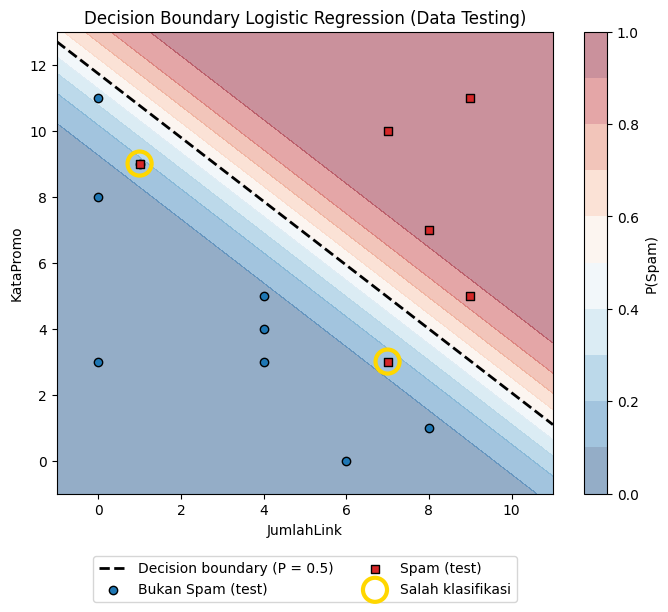

Data testing yang salah diklasifikasikan:


,JumlahLink,KataPromo,Aktual,Prediksi,P(Spam)
0,7,3,1,0,0.150
1,1,9,1,0,0.173


In [20]:
# Jawaban B4
# 1. Persamaan decision boundary: x2 = -(b + m1*x1) / m2
print(f'Decision boundary: KataPromo = -({b_lg:.4f} + {m1_lg:.4f} * JumlahLink) / {m2_lg:.4f}')
print(f'                 = {-b_lg/m2_lg:.4f} + ({-m1_lg/m2_lg:.4f}) * JumlahLink')

# 2. Background probabilitas + decision boundary + data testing
x1_min, x1_max = Xe[:, 0].min() - 1, Xe[:, 0].max() + 1
x2_min, x2_max = Xe[:, 1].min() - 1, Xe[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))
grid_proba = log_reg.predict_proba(np.c_[xx1.ravel(), xx2.ravel()]).reshape(xx1.shape)

salah = ye_pred_test != ye_test          # mask data testing yang salah klasifikasi

plt.figure(figsize=(8, 6))
cs = plt.contourf(xx1, xx2, grid_proba, levels=np.linspace(0, 1, 11), cmap='RdBu_r', alpha=0.45)
plt.colorbar(cs, label='P(Spam)')
x1_line = np.linspace(x1_min, x1_max, 100)
plt.plot(x1_line, -(b_lg + m1_lg * x1_line) / m2_lg, 'k--', lw=2, label='Decision boundary (P = 0.5)')
plt.scatter(Xe_test[ye_test == 0, 0], Xe_test[ye_test == 0, 1], color='tab:blue', edgecolor='k', label='Bukan Spam (test)')
plt.scatter(Xe_test[ye_test == 1, 0], Xe_test[ye_test == 1, 1], color='tab:red', marker='s', edgecolor='k', label='Spam (test)')
# 3. Tandai data yang salah diklasifikasikan
plt.scatter(Xe_test[salah, 0], Xe_test[salah, 1], s=300, facecolors='none', edgecolors='gold', linewidths=3, label='Salah klasifikasi')
plt.xlim(x1_min, x1_max); plt.ylim(x2_min, x2_max)
plt.title('Decision Boundary Logistic Regression (Data Testing)')
plt.xlabel('JumlahLink'); plt.ylabel('KataPromo')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2); plt.show()

print('Data testing yang salah diklasifikasikan:')
df_salah = pd.DataFrame({'JumlahLink': Xe_test[salah, 0], 'KataPromo': Xe_test[salah, 1],
                         'Aktual': ye_test[salah], 'Prediksi': ye_pred_test[salah],
                         'P(Spam)': log_reg.predict_proba(Xe_test[salah]).round(3)})
display(df_salah)

**Jawaban B4 (analisis):**

Persamaan decision boundary-nya:

$$x_2 = -\frac{-10.4196 + 0.8593\,x_1}{0.8887} = 11.7242 - 0.9669\,x_1$$

Email diprediksi spam kalau titiknya berada di atas garis ini. Contohnya, kalau tidak ada link maka kata promosinya harus lebih dari sekitar 11.7, kalau ada 6 link cukup lebih dari sekitar 5.9 kata promosi, dan kalau ada 10 link cukup lebih dari sekitar 2.1 kata promosi.

Ada 2 data testing yang salah diklasifikasikan (dilingkari kuning di grafik). Keduanya sebenarnya spam tetapi diprediksi bukan spam, yaitu JumlahLink 7 dengan KataPromo 3 (P(Spam) = 0.150) dan JumlahLink 1 dengan KataPromo 9 (P(Spam) = 0.173). Keduanya hanya tinggi di salah satu fitur saja (banyak link tapi sedikit kata promosi, atau sebaliknya), jadi skor gabungannya masih di bawah garis. Di data juga ada email yang mirip tetapi labelnya berbeda, misalnya (7, 3) spam sedangkan (7, 4) bukan spam, jadi sebagian kesalahan memang sulit dihindari oleh model linear.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [21]:
# Jawaban B5
proba_test = log_reg.predict_proba(Xe_test)
baris = []
for t in [0.3, 0.5, 0.7]:
    pred_t = (proba_test >= t).astype(int)
    cm_t = confusion_matrix(ye_test, pred_t)
    baris.append({'Threshold': t, 'TN': cm_t[0, 0], 'FP': cm_t[0, 1], 'FN': cm_t[1, 0], 'TP': cm_t[1, 1],
                  'Accuracy': accuracy_score(ye_test, pred_t),
                  'Precision': precision_score(ye_test, pred_t),
                  'Recall': recall_score(ye_test, pred_t),
                  'F1': f1_score(ye_test, pred_t)})
tabel_threshold = pd.DataFrame(baris).set_index('Threshold')
display(tabel_threshold.round(4))

,TN,FP,FN,TP,Accuracy,Precision,Recall,F1
Threshold,,,,,,,,
0.3,8,1,2,4,0.8000,0.8,0.6667,0.7273
0.5,9,0,2,4,0.8667,1.0,0.6667,0.8000
0.7,9,0,2,4,0.8667,1.0,0.6667,0.8000


**Jawaban B5 (analisis):**

| Threshold | TN | FP | FN | TP | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|---|---|---|
| 0.3 | 8 | 1 | 2 | 4 | 0.8000 | 0.8000 | 0.6667 | 0.7273 |
| 0.5 | 9 | 0 | 2 | 4 | 0.8667 | 1.0000 | 0.6667 | 0.8000 |
| 0.7 | 9 | 0 | 2 | 4 | 0.8667 | 1.0000 | 0.6667 | 0.8000 |

Kalau threshold diturunkan, lebih banyak email dianggap spam, jadi recall cenderung naik tetapi precision cenderung turun karena FP bertambah. Kalau threshold dinaikkan, hasilnya sebaliknya: model lebih hati-hati sehingga precision cenderung naik tetapi recall cenderung turun karena FN bertambah.

Pada data testing ini, threshold 0.3 menambah 1 FP (email bukan spam dengan P = 0.344) tanpa menambah recall, karena 2 spam yang lolos hanya punya P = 0.150 dan 0.173, masih di bawah 0.3. Jadi 0.3 lebih jelek dari 0.5. Threshold 0.5 dan 0.7 hasilnya sama persis karena tidak ada email testing yang probabilitasnya berada di antara 0.5 dan 0.7.

Saya memilih threshold 0.7. Dari jawaban B3, FP lebih merugikan daripada FN, jadi saya pilih threshold yang lebih tinggi supaya email biasa lebih jarang masuk ke folder spam. Pada data ini pilihan itu tidak menurunkan recall. Tetapi data testing-nya hanya 15 email, jadi hasil yang sama antara 0.5 dan 0.7 belum cukup untuk membuktikan bahwa 0.7 lebih bagus. Kalau datanya lebih banyak, threshold yang lebih tinggi biasanya akan menurunkan recall.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [22]:
# Jawaban B6
THRESHOLD_PILIHAN = 0.7      # threshold pilihan dari Soal B5

email_baru = pd.DataFrame({'Email': ['E1', 'E2', 'E3', 'E4'],
                           'JumlahLink': [1, 5, 9, 2],
                           'KataPromo': [2, 6, 10, 11]})
p_baru = log_reg.predict_proba(email_baru[['JumlahLink', 'KataPromo']].values)
email_baru['P(Spam)'] = p_baru.round(4)
email_baru['Prediksi'] = np.where(p_baru >= THRESHOLD_PILIHAN, 'Spam', 'Bukan Spam')
display(email_baru)

,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.0004,Bukan Spam
1,E2,5,6,0.3120,Bukan Spam
2,E3,9,10,0.9980,Spam
3,E4,2,11,0.7456,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk klasifikasi karena hasil akhirnya berupa kelas, misalnya spam atau bukan spam, bukan angka kontinu seperti penjualan. Namanya mengandung kata regression karena di dalamnya ada persamaan linear $z = b + m_1x_1 + m_2x_2$ yang menghasilkan sebuah skor. Fungsi sigmoid $\sigma(z) = 1/(1+e^{-z})$ mengubah skor $z$ (yang bisa bernilai berapa saja) menjadi angka antara 0 dan 1 yang dibaca sebagai probabilitas. Probabilitas itu lalu dibandingkan dengan threshold untuk menentukan kelasnya. Contohnya email E3 pada Soal B6 punya skor yang besar sehingga P(Spam)-nya 0.998.

**Jawaban C2:**
Normal equation menghitung parameter langsung sekali jalan dengan rumus $\theta = (X^TX)^{-1}X^Ty$, jadi tidak perlu learning rate dan iterasi. Kekurangannya, rumus ini butuh invers matriks yang berat kalau fiturnya sangat banyak, dan bisa bermasalah kalau $X^TX$ tidak bisa diinvers. Gradient descent mengubah parameter sedikit demi sedikit mengikuti arah gradien loss, sehingga kita harus memilih learning rate dan jumlah iterasi yang tepat (di Soal A5, lr 0.001 terlalu lambat dan lr 0.1 divergen). Gradient descent sebaiknya dipakai kalau datanya besar atau fiturnya sangat banyak, atau kalau modelnya tidak punya rumus langsung seperti Logistic Regression. Di tugas ini, lr 0.02 menghasilkan parameter yang sama dengan normal equation.

**Jawaban C3:**
Model dilatih memakai data training, jadi model sudah "melihat" data itu dan skornya cenderung lebih bagus dari kenyataan. Data testing belum pernah dilihat model, jadi skornya lebih mewakili kemampuan model pada data baru. Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training (termasuk noise-nya), sehingga skor training bagus tetapi skor pada data baru jelek. Pada Soal A4, RMSE training (6.02) dan testing (6.06) hampir sama, jadi tidak terlihat overfitting yang serius.

**Jawaban C4:**
Linear Regression memprediksi nilai kontinu, jadi wajar kalau kesalahannya diukur dari selisih kuadrat antara prediksi dan nilai sebenarnya (MSE). Logistic Regression memprediksi probabilitas untuk label 0 atau 1, dan log loss $-[y\ln p + (1-y)\ln(1-p)]$ cocok untuk itu. Log loss memberi hukuman yang sangat besar kalau model yakin tetapi salah, misalnya memprediksi $p$ mendekati 0 padahal labelnya 1. Kalau MSE dipakai bersama sigmoid, permukaan loss-nya tidak cembung dan gradiennya jadi sangat kecil saat sigmoid sudah jenuh, sehingga training lebih sulit.

**Jawaban C5:**
Penyebab utamanya adalah `random_state` yang berbeda. Pembagian data training dan testing dilakukan secara acak, jadi tiap mahasiswa mendapat data training dan testing yang berbeda. Akibatnya koefisien, intercept, dan nilai evaluasi juga ikut berbeda. Dataset yang dipakai kecil (40 dan 60 data), jadi hasilnya cukup sensitif terhadap pembagian ini. Perbedaan juga bisa muncul kalau teman memakai learning rate atau jumlah iterasi yang berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [16]:
# Jawaban Bonus

**Jawaban Bonus (analisis):**